# Comparison: DoubleMLDeep vs. EmbeddingGemma 2 vs. fine-tuned EmbeddingGemma 2 embeddings

Compares the key results of `04_evaluation.ipynb` across the embeddings used for `emb_*`, `pca_*` and `similarity_cluster_*`. Each run is an execution of `04_evaluation.ipynb` (of `gemma/code` for the first two runs, of this folder for the others) with the parameters given below; the executed notebooks of the additional runs are stored in their output directories.

| embeddings | parameters of `04_evaluation.ipynb` | results |
| --- | --- | --- |
| DoubleMLDeep, text + image, 256 dim. (main analysis; re-run of `main/code/04_evaluation.ipynb`) | `data_dir="../../main/data"` | `../../gemma/outputs/04_evaluation_comparison/finetuned` |
| EmbeddingGemma 2 (off the shelf), text + image, 256 dim. | default of `gemma/code` | `../../gemma/outputs/04_evaluation` |
| **fine-tuned EmbeddingGemma 2, text + image, 256 dim. (main specification of this folder)** | default | `../outputs/04_evaluation` |
| fine-tuned EmbeddingGemma 2, text only, 256 dim. | `txt_only=True` | `../outputs/04_evaluation_comparison/tuned_txt_dim256` |
| fine-tuned EmbeddingGemma 2, text + image, 768 dim. | `emb_dim=768` | `../outputs/04_evaluation_comparison/tuned_txtimg_dim768` |

Note that the cluster-similarity variables are not comparable one-to-one across embeddings: the five clusters are re-estimated (k-means) for every embedding, so `similarity_cluster_k` refers to a different group of products in each run. The loss of the LoRA fine-tuning is computed on the re-normalized 256-dimensional truncation of the embeddings (`head_input` in `data/finetuned/<modality>/embeddinggemma2_tuned_<modality>.json`); the 768-dimensional run uses the full output of the same fine-tuned model.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

palette = sns.color_palette("colorblind")
output_dir = "../outputs/04_evaluation_comparison"
Path(output_dir).mkdir(parents=True, exist_ok=True)

run_dirs = {
    "finetuned": "../../gemma/outputs/04_evaluation_comparison/finetuned",  # DoubleMLDeep (main analysis)
    "gemma_txtimg_dim256": "../../gemma/outputs/04_evaluation",
    "tuned_txtimg_dim256": "../outputs/04_evaluation",
    "tuned_txt_dim256": "../outputs/04_evaluation_comparison/tuned_txt_dim256",
    "tuned_txtimg_dim768": "../outputs/04_evaluation_comparison/tuned_txtimg_dim768",
}
runs = {
    "finetuned": "DoubleMLDeep (txt+img, 256d)",
    "gemma_txtimg_dim256": "EmbeddingGemma 2 (txt+img, 256d)",
    "tuned_txtimg_dim256": "Fine-tuned EmbeddingGemma 2 (txt+img, 256d)",
    "tuned_txt_dim256": "Fine-tuned EmbeddingGemma 2 (txt, 256d)",
    "tuned_txtimg_dim768": "Fine-tuned EmbeddingGemma 2 (txt+img, 768d)",
}
runs = {k: v for k, v in runs.items() if os.path.exists(os.path.join(run_dirs[k], "key_results.json"))}
print(runs)


def load(file_name, **kwargs):
    frames = []
    for run, label in runs.items():
        df = pd.read_csv(os.path.join(run_dirs[run], file_name), **kwargs)
        df.insert(0, "embedding", label)
        frames.append(df)
    return pd.concat(frames)


key_results = {
    run: json.load(open(os.path.join(run_dirs[run], "key_results.json")))
    for run in runs
}

{'finetuned': 'DoubleMLDeep (txt+img, 256d)', 'gemma_txtimg_dim256': 'EmbeddingGemma 2 (txt+img, 256d)', 'tuned_txtimg_dim256': 'Fine-tuned EmbeddingGemma 2 (txt+img, 256d)', 'tuned_txt_dim256': 'Fine-tuned EmbeddingGemma 2 (txt, 256d)', 'tuned_txtimg_dim768': 'Fine-tuned EmbeddingGemma 2 (txt+img, 768d)'}


## Reproduction check

The `finetuned` run (DoubleMLDeep embeddings, `gemma/outputs/04_evaluation_comparison/finetuned`) re-executes the original specification in the environment used for the EmbeddingGemma 2 runs. Its estimates are compared with the outputs stored in `main/code/04_evaluation.ipynb`.

In [2]:
# values printed in the committed outputs of main/code/04_evaluation.ipynb: (value, tolerance given the printed precision)
reference_04 = {
    "Linear lagged": (-0.690266, 5e-7),
    "Linear lagged_and_embeddings": (-0.656960, 5e-7),
    "Linear lagged_and_add_controls": (-0.746364, 5e-7),
    "Linear lagged_and_add_controls_and_emb": (-0.712354, 5e-7),
    "Linear lagged_and_add_controls_and_sim": (-0.722537, 5e-7),
    "plr_embeddings": (-0.623, 5e-4),
    "plr_add_controls": (-0.690, 5e-4),
    "plr_embeddings_add_controls": (-0.697126, 5e-7),
    "plr_sim_add_controls": (-0.691, 5e-4),
    "plr_pca_add_controls": (-0.677, 5e-4),
    "R2 outcome plr_embeddings": (0.8636173876939671, 1e-12),
    "R2 treatment plr_embeddings": (0.9730706950762325, 1e-12),
    "R2 outcome plr_embeddings_add_controls": (0.8910037311081709, 1e-12),
    "R2 treatment plr_embeddings_add_controls": (0.9744150172234399, 1e-12),
    "chi2 p-value clusters: Linear Specification": (0.029984178246390436, 1e-9),
    "chi2 p-value clusters: Linear Specification (Interactions)": (0.053882855916301486, 1e-9),
    "chi2 p-value clusters: PLR Specification": (0.0009061660603696398, 1e-9),
    "sensitivity theta lower (cf=0.03, rho=1)": (-0.829018, 5e-7),
    "sensitivity theta upper (cf=0.03, rho=1)": (-0.565233, 5e-7),
    "sensitivity RV": (0.14856088, 5e-9),
}
if "finetuned" in runs:
    ft_dir = run_dirs["finetuned"]
    ft_plr = pd.read_csv(os.path.join(ft_dir, "plr_ate_estimates.csv")).set_index("model")
    ft_chi2 = pd.read_csv(os.path.join(ft_dir, "chi2_tests.csv")).set_index("model")
    ft_sens = key_results["finetuned"]["sensitivity"]
    rerun = pd.concat(
        [
            pd.read_csv(os.path.join(ft_dir, "linear_ate_estimates.csv")).set_index("model")["coef"],
            ft_plr["coef"],
        ]
    ).to_dict()
    for m in ["plr_embeddings", "plr_embeddings_add_controls"]:
        rerun[f"R2 outcome {m}"] = ft_plr.loc[m, "r2_outcome"]
        rerun[f"R2 treatment {m}"] = ft_plr.loc[m, "r2_treatment"]
    for m in ft_chi2.index:
        rerun[f"chi2 p-value clusters: {m}"] = ft_chi2.loc[m, "p_value_clusters"]
    rerun["sensitivity theta lower (cf=0.03, rho=1)"] = ft_sens["theta_lower_cf003"]
    rerun["sensitivity theta upper (cf=0.03, rho=1)"] = ft_sens["theta_upper_cf003"]
    rerun["sensitivity RV"] = ft_sens["rv"]

    df_repro = pd.DataFrame(reference_04, index=["04_evaluation.ipynb", "tolerance"]).T
    df_repro["re-run"] = pd.Series(rerun)
    df_repro["abs. difference"] = (df_repro["re-run"] - df_repro["04_evaluation.ipynb"]).abs()
    df_repro["reproduced"] = df_repro["abs. difference"] <= df_repro["tolerance"]
    print(f"Reproduced {df_repro['reproduced'].sum()} of {len(df_repro)} reference values")
    display(df_repro)

    # main elasticity table and calibrated sensitivity scenarios written by main/code/04_evaluation.ipynb
    for file_name in ["homogeneous_elasticity_estimates.csv", "sensitivity_calibrated.csv", "sensitivity_robustness_values.csv"]:
        a = pd.read_csv(os.path.join("../../main/output/04_evaluation", file_name)).select_dtypes("number")
        b = pd.read_csv(os.path.join(ft_dir, file_name)).select_dtypes("number")
        print(f"{file_name}: max. abs. difference {np.abs(a.values - b.values).max():.1e}")
        assert np.allclose(a.values, b.values, rtol=0, atol=1e-9)

Reproduced 20 of 20 reference values


,04_evaluation.ipynb,tolerance,re-run,abs. difference,reproduced
Linear lagged,-0.690266,5.000000e-07,-0.690266,4.594517e-07,True
Linear lagged_and_embeddings,-0.656960,5.000000e-07,-0.656960,3.515300e-07,True
Linear lagged_and_add_controls,-0.746364,5.000000e-07,-0.746364,3.374084e-07,True
Linear lagged_and_add_controls_and_emb,-0.712354,5.000000e-07,-0.712354,6.213787e-08,True
Linear lagged_and_add_controls_and_sim,-0.722537,5.000000e-07,-0.722537,1.393222e-07,True
plr_embeddings,-0.623000,5.000000e-04,-0.622685,3.151365e-04,True
plr_add_controls,-0.690000,5.000000e-04,-0.690244,2.443253e-04,True
plr_embeddings_add_controls,-0.697126,5.000000e-07,-0.697126,1.709057e-07,True
plr_sim_add_controls,-0.691000,5.000000e-04,-0.690700,3.000228e-04,True
plr_pca_add_controls,-0.677000,5.000000e-04,-0.677081,8.107994e-05,True


homogeneous_elasticity_estimates.csv: max. abs. difference 0.0e+00
sensitivity_calibrated.csv: max. abs. difference 0.0e+00
sensitivity_robustness_values.csv: max. abs. difference 0.0e+00


## Average effects

In [3]:
df_linear = load("linear_ate_estimates.csv")
df_plr = load("plr_ate_estimates.csv")
df_ate = pd.concat([df_linear, df_plr])
df_ate["estimate (90% CI)"] = df_ate.apply(
    lambda r: f"{r['coef']:.3f} [{r['lower']:.3f}, {r['upper']:.3f}]", axis=1
)
df_ate_table = df_ate.pivot(index="model", columns="embedding", values="estimate (90% CI)")
df_ate_table = df_ate_table.loc[df_ate["model"].unique(), list(runs.values())]
df_ate_table.to_csv(os.path.join(output_dir, "ate_estimates.csv"))
df_ate_table

embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
model,,,,,
Linear lagged,"-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]"
Linear lagged_and_embeddings,"-0.657 [-0.722, -0.592]","-0.681 [-0.746, -0.616]","-0.677 [-0.741, -0.612]","-0.660 [-0.724, -0.595]","-0.664 [-0.729, -0.600]"
Linear lagged_and_add_controls,"-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]"
Linear lagged_and_add_controls_and_emb,"-0.712 [-0.776, -0.649]","-0.731 [-0.795, -0.667]","-0.720 [-0.784, -0.657]","-0.705 [-0.769, -0.642]","-0.708 [-0.772, -0.645]"
Linear lagged_and_add_controls_and_sim,"-0.723 [-0.786, -0.659]","-0.735 [-0.799, -0.670]","-0.765 [-0.830, -0.700]","-0.730 [-0.794, -0.667]","-0.765 [-0.829, -0.700]"
Linear interactions,"-0.727 [-0.791, -0.663]","-0.736 [-0.801, -0.671]","-0.771 [-0.836, -0.706]","-0.731 [-0.795, -0.667]","-0.769 [-0.834, -0.704]"
plr_embeddings,"-0.623 [-0.704, -0.542]","-0.652 [-0.725, -0.580]","-0.652 [-0.726, -0.578]","-0.642 [-0.712, -0.573]","-0.621 [-0.693, -0.548]"
plr_add_controls,"-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]"
plr_embeddings_add_controls,"-0.697 [-0.777, -0.617]","-0.701 [-0.776, -0.625]","-0.667 [-0.743, -0.591]","-0.677 [-0.741, -0.614]","-0.675 [-0.750, -0.599]"


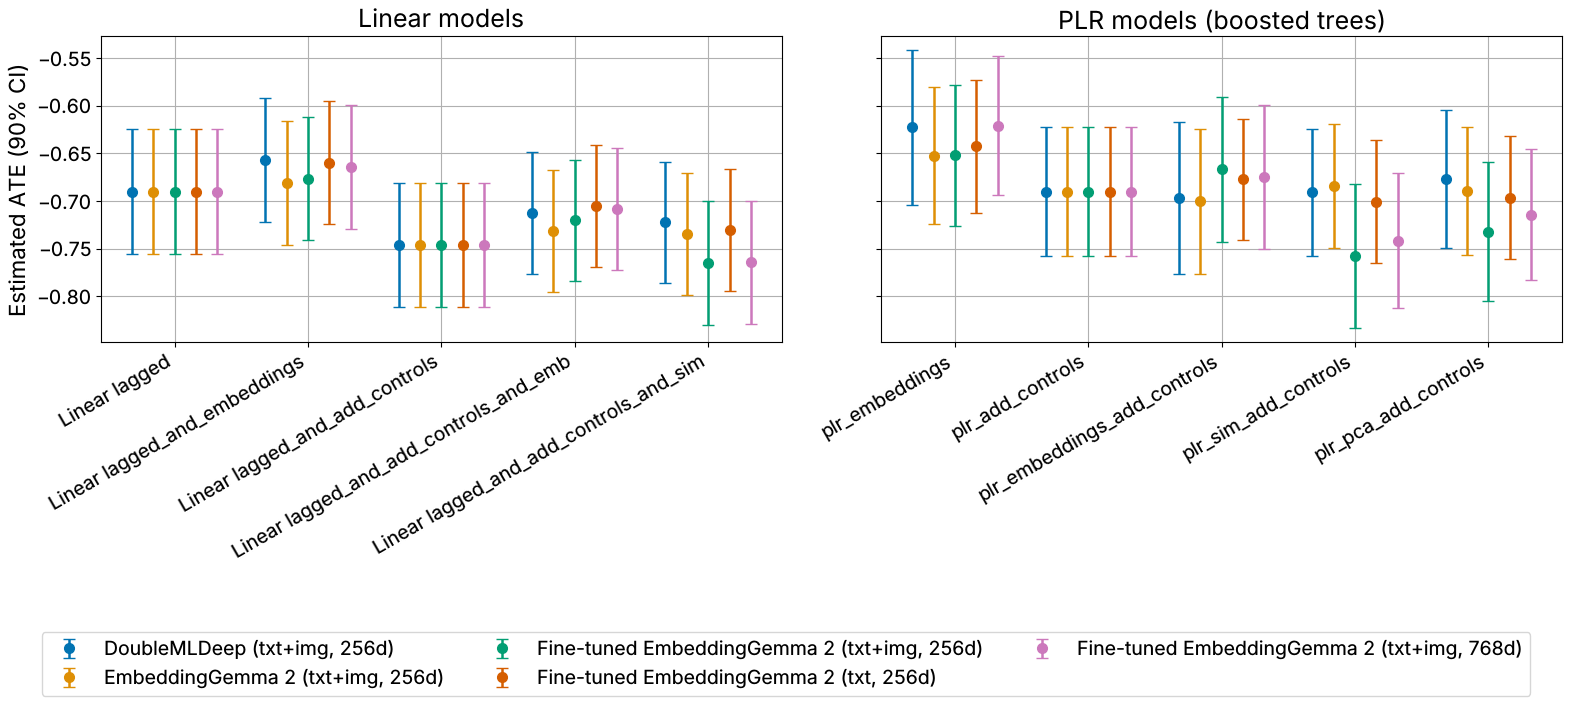

In [4]:
# larger fonts for the Online Appendix (figure printed at text width)
with plt.rc_context({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14}):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    for ax, df, title in [
        (axs[0], df_linear[df_linear["model"] != "Linear interactions"], "Linear models"),
        (axs[1], df_plr, "PLR models (boosted trees)"),
    ]:
        models = list(df["model"].unique())
        x = np.arange(len(models))
        width = 0.8 / len(runs)
        for i, label in enumerate(runs.values()):
            d = df[df["embedding"] == label].set_index("model").loc[models]
            ax.errorbar(
                x + (i - (len(runs) - 1) / 2) * width,
                d["coef"],
                yerr=[d["coef"] - d["lower"], d["upper"] - d["coef"]],
                fmt="o",
                capsize=4,
                markersize=7,
                elinewidth=1.8,
                color=palette[i],
                label=label,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(models, rotation=30, ha="right")
        ax.set_title(title)
        ax.grid(True)
    axs[0].set_ylabel("Estimated ATE (90% CI)")
    handles, labels = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "ate_estimates_comparison.png"), bbox_inches="tight")
    plt.show()

In [5]:
# Nuisance fit of the PLR models (cross-fitted R^2)
df_r2 = df_plr.pivot(index="model", columns="embedding", values="r2_outcome").loc[df_plr["model"].unique(), list(runs.values())]
df_r2_d = df_plr.pivot(index="model", columns="embedding", values="r2_treatment").loc[df_plr["model"].unique(), list(runs.values())]
print("R^2 outcome learner")
display(df_r2.round(4))
print("R^2 treatment learner")
display(df_r2_d.round(4))

R^2 outcome learner


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
model,,,,,
plr_embeddings,0.8636,0.8692,0.8736,0.8730,0.8722
plr_add_controls,0.8991,0.8991,0.8991,0.8991,0.8991
plr_embeddings_add_controls,0.8910,0.8953,0.8986,0.8973,0.8973
plr_sim_add_controls,0.9009,0.8998,0.8988,0.9009,0.8988
plr_pca_add_controls,0.8987,0.8995,0.9009,0.9013,0.9001


R^2 treatment learner


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
model,,,,,
plr_embeddings,0.9731,0.9746,0.9738,0.9743,0.9734
plr_add_controls,0.9775,0.9775,0.9775,0.9775,0.9775
plr_embeddings_add_controls,0.9744,0.9762,0.9751,0.9759,0.9746
plr_sim_add_controls,0.9774,0.9770,0.9772,0.9770,0.9770
plr_pca_add_controls,0.9768,0.9770,0.9775,0.9774,0.9775


## GATEs by most similar cluster

In [6]:
df_gates = load("gate_estimates.csv", index_col=0).reset_index(names="cluster")
df_gates["estimate (95% CI)"] = df_gates.apply(
    lambda r: f"{r['coef']:.3f} [{r['[0.025']:.3f}, {r['0.975]']:.3f}] (n={r['n_obs']:.0f})", axis=1
)
df_gates.pivot(index="cluster", columns="embedding", values="estimate (95% CI)")[list(runs.values())]

embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
cluster,,,,,
Group_similarity_cluster_0,"-0.602 [-0.735, -0.468] (n=6942)","-0.326 [-0.497, -0.155] (n=8199)","-0.467 [-0.621, -0.313] (n=5976)","-0.271 [-0.447, -0.096] (n=11540)","-0.716 [-0.821, -0.611] (n=8713)"
Group_similarity_cluster_1,"-0.907 [-1.070, -0.744] (n=9966)","-0.757 [-0.849, -0.666] (n=10815)","-0.785 [-0.889, -0.680] (n=8984)","-0.721 [-0.809, -0.633] (n=7251)","-0.801 [-0.959, -0.643] (n=6803)"
Group_similarity_cluster_2,"-0.554 [-0.676, -0.431] (n=8285)","-0.442 [-0.621, -0.263] (n=4167)","-0.402 [-0.577, -0.227] (n=8327)","-0.490 [-0.646, -0.333] (n=4372)","-0.289 [-0.477, -0.101] (n=8392)"
Group_similarity_cluster_3,"-0.420 [-0.528, -0.313] (n=8701)","-0.736 [-0.860, -0.613] (n=8920)","-0.684 [-0.783, -0.584] (n=8184)","-0.987 [-1.129, -0.846] (n=7229)","-0.701 [-0.808, -0.594] (n=8034)"
Group_similarity_cluster_4,"-0.641 [-0.758, -0.524] (n=4147)","-0.759 [-1.017, -0.501] (n=5940)","-0.824 [-0.990, -0.658] (n=6570)","-0.497 [-0.612, -0.382] (n=7649)","-0.531 [-0.667, -0.396] (n=6099)"


## CATEs (best linear predictor)

In [7]:
df_cate = load("cate_estimates.csv")
df_cate["estimate (90% CI)"] = df_cate.apply(
    lambda r: f"{r['coef']:.3f} [{r['lower']:.3f}, {r['upper']:.3f}]", axis=1
)
for model in df_cate["model"].unique():
    print(model)
    d = df_cate[df_cate["model"] == model]
    display(d.pivot(index="variable", columns="embedding", values="estimate (90% CI)").loc[d["variable"].unique(), list(runs.values())])

Linear Specification


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,,
intercept,"-0.693 [-0.757, -0.629]","-0.711 [-0.778, -0.644]","-0.692 [-0.758, -0.626]","-0.667 [-0.736, -0.598]","-0.687 [-0.753, -0.620]"
Q_t-1,"-0.165 [-0.256, -0.074]","-0.183 [-0.255, -0.111]","-0.175 [-0.252, -0.097]","-0.184 [-0.269, -0.099]","-0.188 [-0.264, -0.111]"
P_bb_t-1,"-0.014 [-0.097, 0.068]","-0.024 [-0.083, 0.036]","0.023 [-0.071, 0.117]","-0.006 [-0.086, 0.075]","0.015 [-0.077, 0.107]"
similarity_cluster_0,"-0.139 [-2.683, 2.404]","-3.841 [-6.667, -1.016]","-3.550 [-6.214, -0.886]","-2.547 [-5.929, 0.836]","-5.076 [-8.461, -1.691]"
similarity_cluster_1,"-2.881 [-5.600, -0.162]","-6.238 [-10.402, -2.073]","-5.335 [-8.854, -1.816]","-2.618 [-5.582, 0.347]","-3.710 [-6.262, -1.159]"
similarity_cluster_2,"-3.595 [-8.615, 1.426]","-4.330 [-7.533, -1.128]","-3.727 [-6.593, -0.860]","-1.427 [-3.600, 0.745]","-3.711 [-6.646, -0.775]"
similarity_cluster_3,"-4.459 [-10.044, 1.125]","-5.412 [-9.144, -1.679]","-4.453 [-7.620, -1.286]","-2.124 [-4.532, 0.285]","-4.463 [-7.653, -1.274]"
similarity_cluster_4,"-2.245 [-4.074, -0.416]","-4.706 [-7.900, -1.512]","-3.460 [-5.865, -1.055]","-2.514 [-5.609, 0.580]","-3.688 [-6.449, -0.927]"


Linear Specification (Interactions)


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,,
intercept,"-0.703 [-0.768, -0.639]","-0.718 [-0.785, -0.651]","-0.704 [-0.769, -0.638]","-0.676 [-0.745, -0.607]","-0.698 [-0.764, -0.633]"
Q_t-1,"-0.186 [-0.278, -0.095]","-0.190 [-0.261, -0.118]","-0.194 [-0.271, -0.118]","-0.202 [-0.286, -0.118]","-0.208 [-0.284, -0.133]"
P_bb_t-1,"-0.025 [-0.110, 0.059]","-0.029 [-0.089, 0.032]","0.005 [-0.090, 0.101]","-0.019 [-0.100, 0.063]","-0.001 [-0.095, 0.093]"
similarity_cluster_0,"0.134 [-2.423, 2.691]","-3.924 [-6.763, -1.086]","-3.462 [-6.120, -0.804]","-2.407 [-5.813, 0.999]","-5.034 [-8.421, -1.646]"
similarity_cluster_1,"-2.655 [-5.421, 0.111]","-6.408 [-10.591, -2.224]","-5.172 [-8.683, -1.661]","-2.537 [-5.523, 0.448]","-3.732 [-6.287, -1.177]"
similarity_cluster_2,"-3.826 [-8.860, 1.207]","-4.462 [-7.680, -1.244]","-3.596 [-6.456, -0.735]","-1.340 [-3.526, 0.847]","-3.709 [-6.647, -0.770]"
similarity_cluster_3,"-4.672 [-10.273, 0.929]","-5.583 [-9.330, -1.836]","-4.368 [-7.529, -1.208]","-1.995 [-4.422, 0.432]","-4.511 [-7.705, -1.318]"
similarity_cluster_4,"-2.214 [-4.066, -0.361]","-4.907 [-8.118, -1.697]","-3.389 [-5.791, -0.988]","-2.353 [-5.473, 0.766]","-3.675 [-6.439, -0.910]"


PLR Specification


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,,
intercept,"-0.736 [-0.812, -0.659]","-0.693 [-0.767, -0.620]","-0.673 [-0.749, -0.597]","-0.684 [-0.751, -0.618]","-0.675 [-0.753, -0.598]"
Q_t-1,"-0.325 [-0.477, -0.173]","-0.285 [-0.412, -0.159]","-0.252 [-0.373, -0.131]","-0.263 [-0.363, -0.162]","-0.258 [-0.398, -0.119]"
P_bb_t-1,"-0.049 [-0.106, 0.008]","0.009 [-0.039, 0.057]","-0.024 [-0.082, 0.034]","-0.031 [-0.082, 0.020]","-0.063 [-0.121, -0.005]"
similarity_cluster_0,"-2.312 [-4.819, 0.195]","0.555 [-2.931, 4.042]","-5.025 [-7.602, -2.449]","-5.289 [-8.443, -2.134]","-7.642 [-11.097, -4.186]"
similarity_cluster_1,"-7.365 [-10.377, -4.354]","0.173 [-4.788, 5.134]","-7.107 [-10.549, -3.666]","-4.925 [-7.694, -2.155]","-5.493 [-8.097, -2.888]"
similarity_cluster_2,"-6.785 [-12.637, -0.933]","0.586 [-3.197, 4.369]","-5.652 [-8.479, -2.826]","-3.359 [-5.417, -1.302]","-6.466 [-9.551, -3.382]"
similarity_cluster_3,"-8.255 [-14.810, -1.700]","0.081 [-4.295, 4.457]","-6.521 [-9.614, -3.427]","-4.074 [-6.318, -1.830]","-7.422 [-10.723, -4.121]"
similarity_cluster_4,"-4.559 [-6.702, -2.417]","0.174 [-3.521, 3.869]","-4.533 [-6.872, -2.193]","-4.822 [-7.746, -1.899]","-5.879 [-8.695, -3.063]"


In [8]:
df_chi2 = load("chi2_tests.csv")
print("Chi^2 tests: p-values for H0 'no heterogeneity along the cluster similarities' / 'no heterogeneity at all'")
display(df_chi2.pivot(index="model", columns="embedding", values="p_value_clusters")[list(runs.values())])
display(df_chi2.pivot(index="model", columns="embedding", values="p_value_heterogeneity")[list(runs.values())])

Chi^2 tests: p-values for H0 'no heterogeneity along the cluster similarities' / 'no heterogeneity at all'


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
model,,,,,
Linear Specification,0.029984,0.001166,0.007567,0.024411,0.007523
Linear Specification (Interactions),0.053883,0.000687,0.007585,0.018610,0.006171
PLR Specification,0.000906,0.011642,0.002005,0.004364,0.000267


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
model,,,,,
Linear Specification,5.046780e-06,1.289322e-07,3.382113e-07,1.594186e-05,3.991276e-07
Linear Specification (Interactions),3.777124e-06,3.921103e-08,7.664077e-08,4.345283e-06,5.598695e-08
PLR Specification,4.323589e-08,3.530540e-05,4.951515e-06,5.637708e-07,1.435191e-07


In [9]:
df_var = load("cate_variance_explained.csv", index_col=0).reset_index(names="regressors")
df_var.melt(id_vars=["embedding", "regressors"], var_name="model", value_name="R2").pivot(
    index=["model", "regressors"], columns="embedding", values="R2"
)[list(runs.values())].round(3)

embedding                                             DoubleMLDeep (txt+img, 256d)  \
model                               regressors                                       
Linear Specification                embeddings                               0.728   
                                    lagged variables                         0.740   
                                    similarities                             0.678   
Linear Specification (Interactions) embeddings                               0.686   
                                    lagged variables                         0.775   
                                    similarities                             0.628   
PLR Specification                   embeddings                               0.584   
                                    lagged variables                         0.747   
                                    similarities                             0.506   

embedding                                             EmbeddingGemma 2 (txt+img, 256d)  \
model                               regressors                                           
Linear Specification                embeddings                                   0.687   
                                    lagged variables                             0.591   
                                    similarities                                 0.567   
Linear Specification (Interactions) embeddings                                   0.687   
                                    lagged variables                             0.587   
                                    similarities                                 0.565   
PLR Specification                   embeddings                                   0.486   
                                    lagged variables                             0.776   
                                    similarities                                 0.297   

embedding                                             Fine-tuned EmbeddingGemma 2 (txt+img, 256d)  \
model                               regressors                                                      
Linear Specification                embeddings                                              0.724   
                                    lagged variables                                        0.621   
                                    similarities                                            0.489   
Linear Specification (Interactions) embeddings                                              0.701   
                                    lagged variables                                        0.649   
                                    similarities                                            0.449   
PLR Specification                   embeddings                                              0.682   
                                    lagged variables                                        0.772   
                                    similarities                                            0.420   

embedding                                             Fine-tuned EmbeddingGemma 2 (txt, 256d)  \
model                               regressors                                                  
Linear Specification                embeddings                                          0.672   
                                    lagged variables                                    0.671   
                                    similarities                                        0.542   
Linear Specification (Interactions) embeddings                                          0.642   
                                    lagged variables                                    0.694   
                                    similarities                                        0.501   
PLR Specification                   embeddings                                          0.576   
                                    lagged variables                         

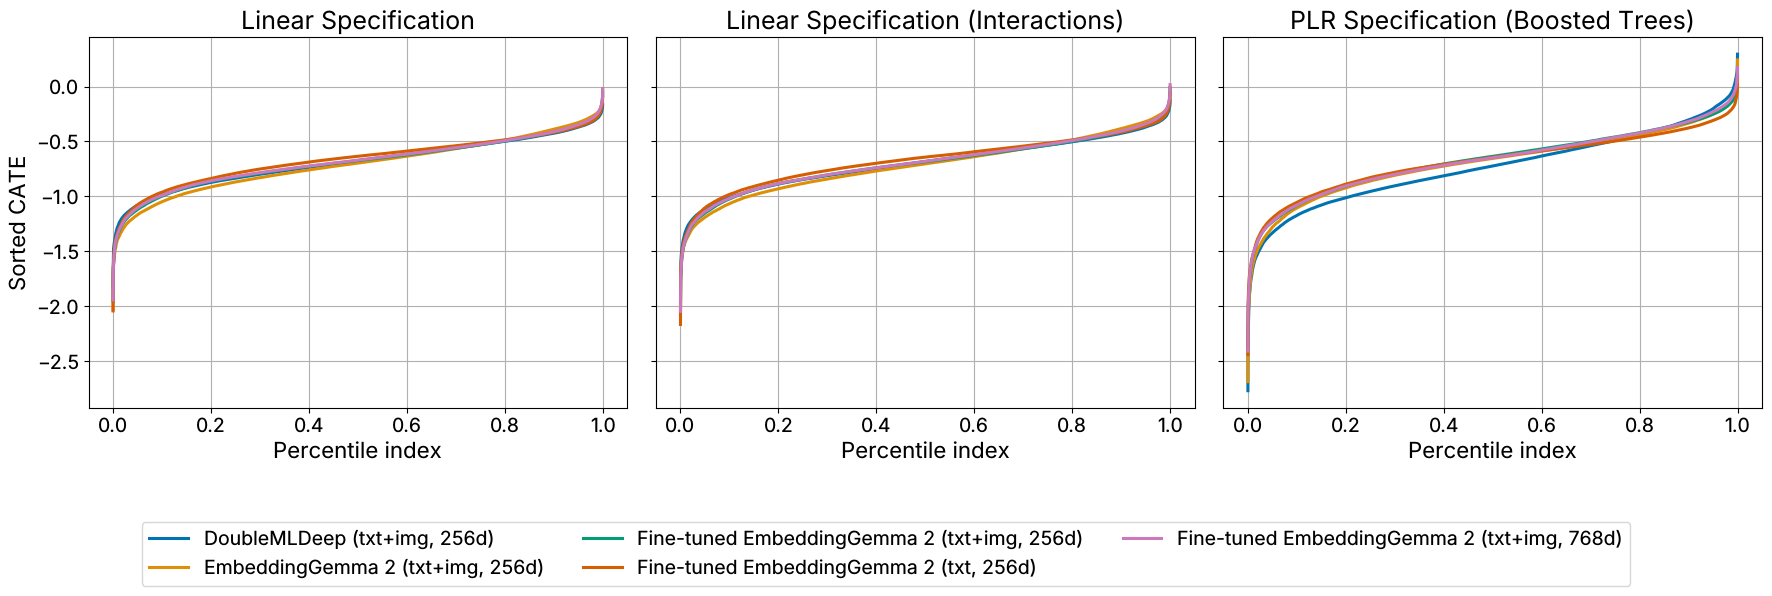

0.05   0.25  \
DoubleMLDeep (txt+img, 256d)                SortEff_lin      -1.080 -0.833   
                                            SortEff_tab_dml  -1.112 -0.846   
                                            SortEff_deep_dml -1.331 -0.954   
EmbeddingGemma 2 (txt+img, 256d)            SortEff_lin      -1.168 -0.868   
                                            SortEff_tab_dml  -1.190 -0.882   
                                            SortEff_deep_dml -1.280 -0.860   
Fine-tuned EmbeddingGemma 2 (txt+img, 256d) SortEff_lin      -1.118 -0.823   
                                            SortEff_tab_dml  -1.151 -0.842   
                                            SortEff_deep_dml -1.230 -0.844   
Fine-tuned EmbeddingGemma 2 (txt, 256d)     SortEff_lin      -1.077 -0.789   
                                            SortEff_tab_dml  -1.104 -0.804   
                                            SortEff_deep_dml -1.197 -0.827   
Fine-tuned EmbeddingGemma 2 (txt+img, 768d) SortEff_lin      -1.103 -0.818   
                                            SortEff_tab_dml  -1.137 -0.842   
                                            SortEff_deep_dml -1.227 -0.847   

                                                               0.50   0.75  \
DoubleMLDeep (txt+img, 256d)                SortEff_lin      -0.674 -0.529   
                                            SortEff_tab_dml  -0.681 -0.534   
                                            SortEff_deep_dml -0.723 -0.491   
EmbeddingGemma 2 (txt+img, 256d)            SortEff_lin      -0.696 -0.529   
                                            SortEff_tab_dml  -0.703 -0.529   
                                            SortEff_deep_dml -0.654 -0.481   
Fine-tuned EmbeddingGemma 2 (txt+img, 256d) SortEff_lin      -0.674 -0.530   
                                            SortEff_tab_dml  -0.684 -0.534   
                                            SortEff_deep_dml -0.635 -0.458   
Fine-tuned EmbeddingGemma 2 (txt, 256d)     SortEff_lin      -0.635 -0.513   
                                            SortEff_tab_dml  -0.642 -0.515   
                                            SortEff_deep_dml -0.644 -0.496   
Fine-tuned EmbeddingGemma 2 (txt+img, 768d) SortEff_lin      -0.669 -0.526   
                                            SortEff_tab_dml  -0.681 -0.526   
                                            SortEff_deep_dml -0.648 -0.462   

                                                               0.95  
DoubleMLDeep (txt+img, 256d)                SortEff_lin      -0.370  
                                            SortEff_tab_dml  -0.369  
                                            SortEff_deep_dml -0.202  
EmbeddingGemma 2 (txt+img, 256d)            SortEff_lin      -0.328  
                                            SortEff_tab_dml  -0.318  
                                            SortEff_deep_dml -0.251  
Fine-tuned EmbeddingGemma 2 (txt+img, 256d) SortEff_lin      -0.353  
                                            SortEff_tab_dml  -0.350  
                                            SortEff_deep_dml -0.252  
Fine-tuned EmbeddingGemma 2 (txt, 256d)     SortEff_lin      -0.365  
                                            SortEff_tab_dml  -0.358  
                                            SortEff_deep_dml -0.308  
Fine-tuned EmbeddingGemma 2 (txt+img, 768d) SortEff_lin      -0.347  
                                            SortEff_tab_dml  -0.338  
                                            SortEff_deep_dml -0.231

In [10]:
# Distribution of the per-observation CATEs
# larger fonts for the Online Appendix (figure printed at text width)
with plt.rc_context({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14}):
    fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    titles = {
        "SortEff_lin": "Linear Specification",
        "SortEff_tab_dml": "Linear Specification (Interactions)",
        "SortEff_deep_dml": "PLR Specification (Boosted Trees)",
    }
    sorted_effects = {
        label: pd.read_csv(os.path.join(run_dirs[run], "sorted_effects.csv"))
        for run, label in runs.items()
    }
    for ax, (col, title) in zip(axs, titles.items()):
        for i, (label, df) in enumerate(sorted_effects.items()):
            values = np.sort(df[col].values)
            ax.plot(np.linspace(0, 1, len(values)), values, color=palette[i], label=label, linewidth=2.2)
        ax.set_title(title)
        ax.set_xlabel("Percentile index")
        ax.grid(True)
    axs[0].set_ylabel("Sorted CATE")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "sorted_effects_comparison.png"), bbox_inches="tight")
    plt.show()

pd.DataFrame(
    {
        (label, col): df[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
        for label, df in sorted_effects.items()
        for col in titles
    }
).T.round(3)

In [11]:
# Correlation of the per-observation CATEs (PLR specification) across embeddings
df_corr = pd.DataFrame({label: df["SortEff_deep_dml"].values for label, df in sorted_effects.items()})
df_corr.corr().round(3)

,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
"DoubleMLDeep (txt+img, 256d)",1.000,0.773,0.816,0.794,0.811
"EmbeddingGemma 2 (txt+img, 256d)",0.773,1.000,0.901,0.865,0.879
"Fine-tuned EmbeddingGemma 2 (txt+img, 256d)",0.816,0.901,1.000,0.916,0.989
"Fine-tuned EmbeddingGemma 2 (txt, 256d)",0.794,0.865,0.916,1.000,0.901
"Fine-tuned EmbeddingGemma 2 (txt+img, 768d)",0.811,0.879,0.989,0.901,1.000


## Sensitivity analysis (PLR with embeddings and additional controls)

In [12]:
df_sens = pd.DataFrame({runs[run]: res["sensitivity"] for run, res in key_results.items()})
df_sens.to_csv(os.path.join(output_dir, "sensitivity_comparison.csv"))
df_sens.round(4)

,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
theta,-0.6971,-0.7005,-0.6667,-0.6771,-0.6746
theta_lower_cf003,-0.8290,-0.8347,-0.7958,-0.8091,-0.8031
theta_upper_cf003,-0.5652,-0.5663,-0.5377,-0.5451,-0.5462
ci_lower_cf003,-0.8896,-0.8919,-0.8525,-0.8571,-0.8601
ci_upper_cf003,-0.5010,-0.5052,-0.4754,-0.4937,-0.4851
rv,0.1486,0.1469,0.1455,0.1445,0.1477
rva,0.1337,0.1329,0.1301,0.1322,0.1329
implied_rho,0.1503,0.0844,0.0300,0.0652,0.1203
partial_r2_outcome,0.2008,0.1995,0.1983,0.1912,0.1969
partial_r2_treatment,0.0499,0.0652,0.0519,0.0618,0.0443


Bias bounds and one-sided 90% confidence bounds, `[ci_lower] theta_lower .. theta_upper [ci_upper]`, with $R^2_Y = R^2_D$ equal to the residual share and $\rho = 1$: at the calibration of each run (its own observed-covariate benchmark $r_0$ and the 1.5 and 2 multiples) and at the residual shares of the main analysis (DoubleMLDeep embeddings).

In [13]:
def format_bounds(df):
    df = df.copy()
    df["share"] = (100 * df["share"]).round(2).astype(str) + "%"
    df["bounds [CI]"] = df.apply(
        lambda r: f"[{r['ci_lower']:.3f}] {r['theta_lower']:.3f} .. {r['theta_upper']:.3f} [{r['ci_upper']:.3f}]", axis=1
    )
    return df


df_sens_own = format_bounds(load("sensitivity_calibrated.csv"))
df_sens_main_shares = format_bounds(load("sensitivity_main_shares.csv"))
print("Calibration of each run (own benchmark)")
display(df_sens_own.pivot(index="multiplier", columns="embedding", values=["share", "bounds [CI]"]).swaplevel(axis=1)[list(runs.values())])
print("Residual shares of the main analysis")
display(df_sens_main_shares.pivot(index="share", columns="embedding", values="bounds [CI]")[list(runs.values())])
df_rv = load("sensitivity_robustness_values.csv")
df_rv.pivot(index="null_hypothesis", columns="embedding", values=["RV", "RVa"]).round(4)

Calibration of each run (own benchmark)


embedding  DoubleMLDeep (txt+img, 256d)                                      \
                                  share                         bounds [CI]   
multiplier                                                                    
1.0                               1.53%  [-0.825] -0.764 .. -0.630 [-0.567]   
1.5                                2.3%  [-0.859] -0.798 .. -0.596 [-0.533]   
2.0                               3.06%  [-0.893] -0.832 .. -0.562 [-0.498]   

embedding  EmbeddingGemma 2 (txt+img, 256d)  \
                                      share   
multiplier                                    
1.0                                   0.99%   
1.5                                   1.49%   
2.0                                   1.98%   

embedding                                       \
                                   bounds [CI]   
multiplier                                       
1.0         [-0.803] -0.744 .. -0.657 [-0.597]   
1.5         [-0.824] -0.766 .. -0.635 [-0.575]   
2.0         [-0.846] -0.789 .. -0.612 [-0.552]   

embedding  Fine-tuned EmbeddingGemma 2 (txt+img, 256d)  \
                                                 share   
multiplier                                               
1.0                                              0.31%   
1.5                                              0.47%   
2.0                                              0.62%   

embedding                                       \
                                   bounds [CI]   
multiplier                                       
1.0         [-0.739] -0.680 .. -0.654 [-0.594]   
1.5         [-0.745] -0.687 .. -0.647 [-0.587]   
2.0         [-0.752] -0.693 .. -0.640 [-0.580]   

embedding  Fine-tuned EmbeddingGemma 2 (txt, 256d)  \
                                             share   
multiplier                                           
1.0                                          0.73%   
1.5                                          1.09%   
2.0                                          1.46%   

embedding                                       \
                                   bounds [CI]   
multiplier                                       
1.0         [-0.758] -0.709 .. -0.645 [-0.595]   
1.5         [-0.774] -0.725 .. -0.629 [-0.579]   
2.0         [-0.790] -0.741 .. -0.613 [-0.563]   

embedding  Fine-tuned EmbeddingGemma 2 (txt+img, 768d)  \
                                                 share   
multiplier                                               
1.0                                              1.14%   
1.5                                              1.71%   
2.0                                              2.29%   

embedding                                       
                                   bounds [CI]  
multiplier                                      
1.0         [-0.781] -0.723 .. -0.626 [-0.567]  
1.5         [-0.805] -0.748 .. -0.602 [-0.542]  
2.0         [-0.830] -0.772 .. -0.577 [-0.517]

Residual shares of the main analysis


embedding,"DoubleMLDeep (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 256d)","Fine-tuned EmbeddingGemma 2 (txt, 256d)","Fine-tuned EmbeddingGemma 2 (txt+img, 768d)"
share,,,,,
1.53%,[-0.825] -0.764 .. -0.630 [-0.567],[-0.827] -0.769 .. -0.633 [-0.572],[-0.790] -0.732 .. -0.601 [-0.541],[-0.793] -0.744 .. -0.610 [-0.560],[-0.798] -0.740 .. -0.609 [-0.550]
2.3%,[-0.859] -0.798 .. -0.596 [-0.533],[-0.861] -0.803 .. -0.598 [-0.537],[-0.823] -0.765 .. -0.568 [-0.507],[-0.826] -0.778 .. -0.576 [-0.525],[-0.830] -0.773 .. -0.577 [-0.516]
3.06%,[-0.893] -0.832 .. -0.562 [-0.498],[-0.895] -0.838 .. -0.563 [-0.502],[-0.855] -0.799 .. -0.535 [-0.473],[-0.860] -0.812 .. -0.542 [-0.491],[-0.863] -0.806 .. -0.543 [-0.482]


RV                                   \
embedding       DoubleMLDeep (txt+img, 256d) EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                                                 
-0.5                                  0.0445                           0.0445   
 0.0                                  0.1486                           0.1469   

                                                             \
embedding       Fine-tuned EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                               
-0.5                                                 0.0386   
 0.0                                                 0.1455   

                                                             \
embedding       Fine-tuned EmbeddingGemma 2 (txt+img, 768d)   
null_hypothesis                                               
-0.5                                                 0.0406   
 0.0                                                 0.1477   

                                                         \
embedding       Fine-tuned EmbeddingGemma 2 (txt, 256d)   
null_hypothesis                                           
-0.5                                             0.0401   
 0.0                                             0.1445   

                                         RVa                                   \
embedding       DoubleMLDeep (txt+img, 256d) EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                                                 
-0.5                                  0.0302                           0.0311   
 0.0                                  0.1337                           0.1329   

                                                             \
embedding       Fine-tuned EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                               
-0.5                                                 0.0245   
 0.0                                                 0.1301   

                                                             \
embedding       Fine-tuned EmbeddingGemma 2 (txt+img, 768d)   
null_hypothesis                                               
-0.5                                                 0.0266   
 0.0                                                 0.1329   

                                                         
embedding       Fine-tuned EmbeddingGemma 2 (txt, 256d)  
null_hypothesis                                          
-0.5                                             0.0286  
 0.0                                             0.1322